[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anderson-perez/IAC/blob/main/4%20-%20Aprendizado%20Profundo/Fundamentos_CNN_Keras.ipynb)

# Inteligência Artificial e Computacional

## Segunda Parte da Disciplina

# Informações:

- Prof. Anderson Luiz Fernandes Perez
- Contato: anderson.perez@ufsc.br | anderson.lfp@gmail.com
- Os materiais da disciplina estarão disponíveis no github (https://github.com/anderson-perez/IAC.git)

# Redes Neurais Convolucionais (CNN)

As Redes Neurais Convolucionais (Convolutional Neural Networks – CNNs) são uma classe de redes neurais artificiais especialmente desenvolvida para processar dados que apresentam estrutura espacial, como imagens. Diferentemente das redes Multilayer Perceptron (MLP), as CNNs utilizam camadas convolucionais que aplicam filtros para extrair automaticamente características relevantes, como bordas, texturas, formas e padrões mais complexos. Sua arquitetura geralmente combina camadas convolucionais, funções de ativação, operações de pooling e camadas densas, permitindo aprender representações hierárquicas dos dados. 

Por explorarem a conectividade local e o compartilhamento de pesos, as CNNs são particularmente eficientes em tarefas de visão computacional, como classificação de imagens, detecção de objetos e reconhecimento de padrões.

In [2]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

random.seed(42)
np.random.seed(42)
keras.utils.set_random_seed(42)

## Definição de uma Imagem Digital

Uma imagem em escala de cinza pode ser representada por uma matriz $I\in\mathbb{R}^{H\times W}$, em que cada elemento representa a intensidade de um pixel. Em imagens RGB, a representação usual é um tensor $H\times W\times 3$ (canais vermelho, verde e azul). Uma imagem **28 × 28** em escala de cinza possui **784 valores**.

Imagens com pixels de 8 bits usam normalmente valores inteiros entre **0 e 255**. Para treinar redes neurais, é comum normalizar esses valores para o intervalo **[0, 1]**.

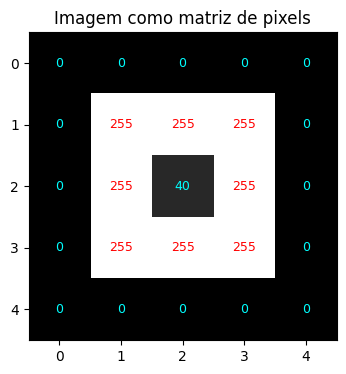

In [4]:
imagem_exemplo = np.array([[0, 0, 0, 0, 0],
                           [0, 255, 255, 255, 0],
                           [0, 255, 40, 255, 0],
                           [0, 255, 255, 255, 0],
                           [0, 0, 0, 0, 0]], dtype=np.uint8)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(imagem_exemplo, cmap='gray', vmin=0, vmax=255)

for i in range(5):
    for j in range(5):
        ax.text(j, i, str(imagem_exemplo[i, j]), ha='center', va='center',
                color='red' if imagem_exemplo[i, j] > 150 else 'cyan', fontsize=9)

ax.set_title('Imagem como matriz de pixels')
ax.set_xticks(range(5)); ax.set_yticks(range(5))
plt.show()

### Exemplo: Dataset Fashion-MNIST

O Fashion-MNIST contém **60.000 imagens de treinamento e 10.000 imagens de teste**, com 10 classes de vestuário. Cada imagem tem 28 × 28 pixels, em escala de cinza. Reservaremos 10.000 imagens do conjunto original de treinamento para validação; **o teste será mantido intocado até a avaliação final**.

In [7]:
import ssl
import certifi

ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

In [8]:
(X_train_full, y_train_full), (X_test_raw, y_test) = keras.datasets.fashion_mnist.load_data()

nomes_classes = ['Camiseta/top', 'Calça', 'Pulôver', 'Vestido', 'Casaco',
                 'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota']
print('Treinamento original:', X_train_full.shape, y_train_full.shape)
print('Teste:', X_test_raw.shape, y_test.shape)
print('Tipo:', X_train_full.dtype, 'Intervalo:', (X_train_full.min(), X_train_full.max()))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Treinamento original: (60000, 28, 28) (60000,)
Teste: (10000, 28, 28) (10000,)
Tipo: uint8 Intervalo: (np.uint8(0), np.uint8(255))


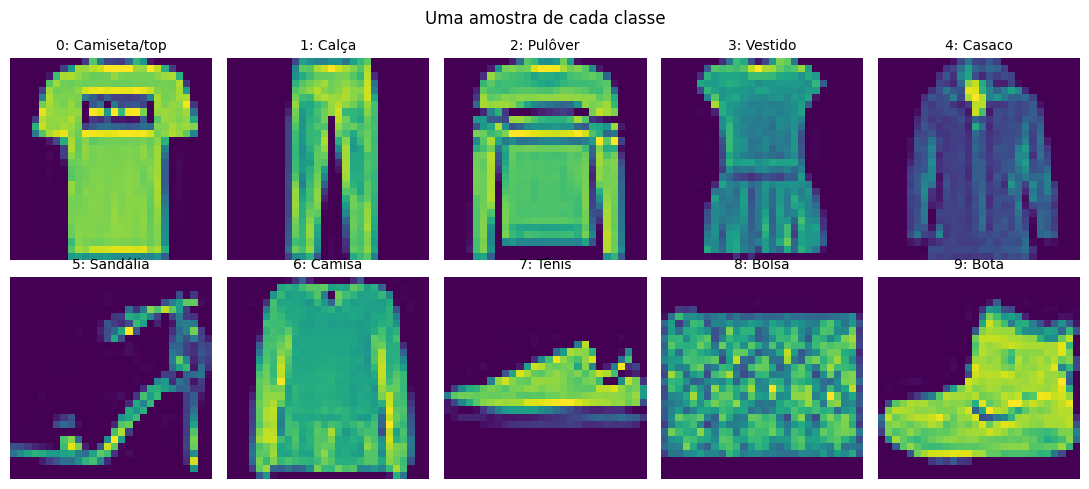

Primeiros 5 × 5 pixels da primeira imagem:
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


In [10]:
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for classe, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y_train_full == classe)[0]
    ax.imshow(X_train_full[idx])
    ax.set_title(f'{classe}: {nomes_classes[classe]}', fontsize=10)
    ax.axis('off')
plt.suptitle('Uma amostra de cada classe')
plt.tight_layout(); plt.show()

print('Primeiros 5 × 5 pixels da primeira imagem:\n', X_train_full[0, :5, :5])

### Preparação e Divisão dos Dados

A MLP recebe tensores 28 × 28 e aplica `Flatten` internamente; a CNN recebe tensores 28 × 28 × 1.

In [11]:
from sklearn.model_selection import train_test_split
indices = np.arange(len(X_train_full))
idx_treino, idx_val = train_test_split(indices, test_size=10_000,
                                      stratify=y_train_full, random_state=SEED)
X_train = X_train_full[idx_treino].astype('float32') / 255.0
X_val = X_train_full[idx_val].astype('float32') / 255.0
X_test = X_test_raw.astype('float32') / 255.0
y_train, y_val = y_train_full[idx_treino], y_train_full[idx_val]
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]
print('Treino:', X_train.shape, 'Validação:', X_val.shape, 'Teste:', X_test.shape)
print('CNN:', X_train_cnn.shape)
print('Distribuição treino:', np.bincount(y_train))

Treino: (50000, 28, 28) Validação: (10000, 28, 28) Teste: (10000, 28, 28)
CNN: (50000, 28, 28, 1)
Distribuição treino: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


## Classificação com MLP

Uma MLP (Multilayer Perceptron) é uma rede com camadas densas. Para processar uma imagem, é comum aplicar **Flatten**, que converte uma matriz 28 × 28 em um vetor de 784 valores.

A MLP pode aprender relações espaciais, porém não possui, por construção, conectividade local nem compartilhamento de pesos. Além disso, camadas densas podem exigir muitos parâmetros para imagens maiores.

Para uma camada densa com $n_{in}$ entradas e $n_{out}$ neurônios, o número de parâmetros (com vieses) é $(n_{in}+1)n_{out}$.

In [12]:
mlp = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='MLP')
mlp.summary()
print('Parâmetros MLP:', mlp.count_params())

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros MLP: 109386


### Treinamento

A rede será treinada por 10 épocas, sem ajuste de hiperparâmetros baseado no teste. O tempo de execução varia conforme o hardware.

In [13]:
EPOCAS = 10
BATCH_SIZE = 128

def compilar(modelo):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

def treinar(modelo, X, y, Xv, yv):
    compilar(modelo)
    inicio = time.perf_counter()
    historico = modelo.fit(X, y, validation_data=(Xv, yv),
                           epochs=EPOCAS, batch_size=BATCH_SIZE, verbose=1)
    return historico, time.perf_counter() - inicio

hist_mlp, tempo_mlp = treinar(mlp, X_train, y_train, X_val, y_val)

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8008 - loss: 0.5705 - val_accuracy: 0.8472 - val_loss: 0.4255
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8540 - loss: 0.4072 - val_accuracy: 0.8697 - val_loss: 0.3730
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8676 - loss: 0.3633 - val_accuracy: 0.8794 - val_loss: 0.3425
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8771 - loss: 0.3369 - val_accuracy: 0.8798 - val_loss: 0.3354
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8844 - loss: 0.3164 - val_accuracy: 0.8847 - val_loss: 0.3201
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8893 - loss: 0.3010 - val_accuracy: 0.8894 - val_loss: 0.3103
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8933 - loss: 0.2860 - val_accuracy: 0.8899 - val_loss: 0.3070
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8982 - loss: 0.2733 - val_accuracy: 0.

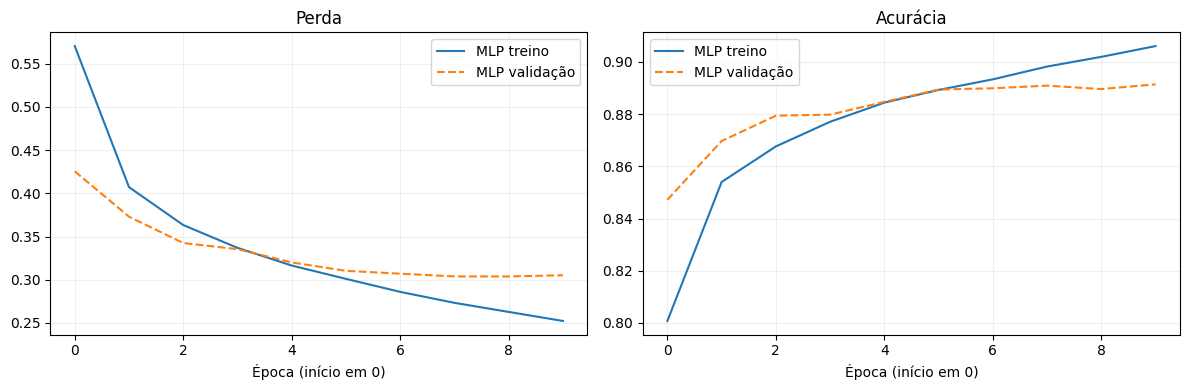

In [14]:
def plotar_historicos(historicos):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for nome, hist in historicos.items():
        axs[0].plot(hist.history['loss'], label=f'{nome} treino')
        axs[0].plot(hist.history['val_loss'], '--', label=f'{nome} validação')
        axs[1].plot(hist.history['accuracy'], label=f'{nome} treino')
        axs[1].plot(hist.history['val_accuracy'], '--', label=f'{nome} validação')
    axs[0].set_title('Perda'); axs[1].set_title('Acurácia')
    for ax in axs:
        ax.set_xlabel('Época (início em 0)'); ax.grid(alpha=.2); ax.legend()
    plt.tight_layout(); plt.show()

plotar_historicos({'MLP': hist_mlp})

## Redes Convolucionais

CNNs introduzem **conectividade local** (cada filtro examina uma pequena região) e **compartilhamento de pesos** (o mesmo filtro percorre posições diferentes). A aplicação de um filtro gera um **mapa de características** (*feature map*).

A arquitetura típica combina convoluções, funções de ativação, operações de redução espacial e, ao final, uma cabeça classificadora. As primeiras camadas podem aprender padrões simples, enquanto camadas mais profundas podem combinar esses padrões em características mais complexas.

> Em implementações de aprendizado profundo, `Conv2D` normalmente calcula **correlação cruzada** (sem inverter o kernel), embora a operação seja chamada de convolução.

## Filtros Convolucionais

### Filtro 2D: cálculo manual

Para uma entrada $I$ e um kernel $K$ de tamanho $k_h\times k_w$, a saída sem padding e com stride 1 pode ser escrita como:

$$Y[i,j]=\sum_{u=0}^{k_h-1}\sum_{v=0}^{k_w-1}I[i+u,j+v]K[u,v].$$

Essa expressão corresponde à **correlação cruzada**, a convenção usada pelas camadas `Conv2D`. Primeiro implementaremos a operação sem usar redes neurais.

In [15]:
def correlacao2d(imagem, kernel, stride=1):
    imagem = np.asarray(imagem, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    h, w = imagem.shape
    kh, kw = kernel.shape
    if stride < 1 or kh > h or kw > w:
        raise ValueError('Dimensões ou stride inválidos')
    oh = (h - kh) // stride + 1
    ow = (w - kw) // stride + 1
    saida = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            regiao = imagem[i*stride:i*stride+kh, j*stride:j*stride+kw]
            saida[i, j] = np.sum(regiao * kernel)
    return saida

entrada = np.array([[1, 2, 0, 1], [3, 1, 2, 0],
                    [0, 1, 3, 2], [2, 0, 1, 1]])
filtro = np.array([[1, 0], [0, -1]])
resultado = correlacao2d(entrada, filtro)
print('Entrada:\n', entrada)
print('Filtro:\n', filtro)
print('Primeira posição: 1×1 + 2×0 + 3×0 + 1×(-1) =', resultado[0, 0])
print('Saída:\n', resultado)

Entrada:
 [[1 2 0 1]
 [3 1 2 0]
 [0 1 3 2]
 [2 0 1 1]]
Filtro:
 [[ 1  0]
 [ 0 -1]]
Primeira posição: 1×1 + 2×0 + 3×0 + 1×(-1) = 0.0
Saída:
 [[ 0.  0.  0.]
 [ 2. -2.  0.]
 [ 0.  0.  2.]]


### Filtros em Imagens Reais

Filtros manuais podem destacar bordas horizontais, verticais ou suavizar uma imagem. A visualização abaixo mostra a resposta **bruta** dos filtros, sem aplicar ReLU.

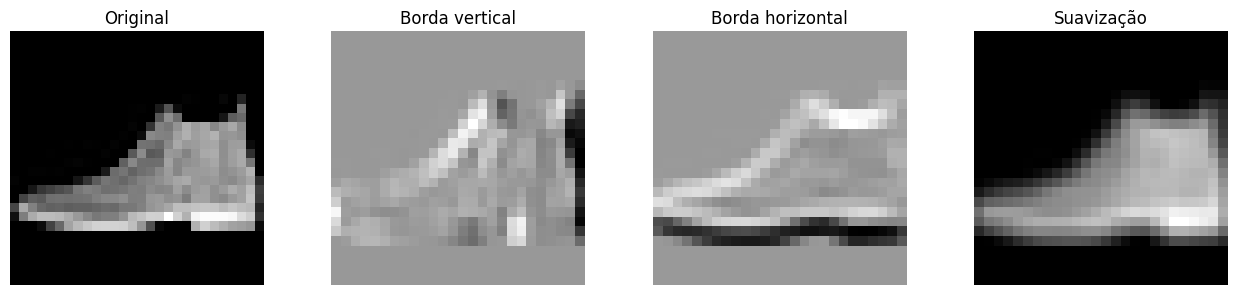

In [16]:
imagem = X_test[0]
filtros = {
    'Borda vertical': np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]),
    'Borda horizontal': np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]]),
    'Suavização': np.ones((3, 3)) / 9
}
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
axs[0].imshow(imagem, cmap='gray'); axs[0].set_title('Original')
for ax, (nome, kernel) in zip(axs[1:], filtros.items()):
    ax.imshow(correlacao2d(imagem, kernel), cmap='gray')
    ax.set_title(nome)
for ax in axs: ax.axis('off')
plt.tight_layout(); plt.show()

### Stride, Padding e Tamanho de Saída

- **Stride:** deslocamento do filtro entre posições sucessivas.
- **Padding:** pixels acrescentados às bordas. `valid` não adiciona padding; `same` normalmente preserva a dimensão espacial quando o stride é 1.
- **Número de filtros:** quantidade de canais de saída da convolução.

Para uma dimensão de entrada $N$, kernel $K$, padding $P$ (em cada lado) e stride $S$, o tamanho de saída é:

$$N_{out}=\left\lfloor\frac{N+2P-K}{S}\right\rfloor+1.$$

Com kernel 3 × 3, stride 1 e padding `valid`, 28 × 28 se torna 26 × 26. Com `same`, permanece 28 × 28.

In [19]:
exemplo = keras.ops.zeros((1, 28, 28, 1))
for padding, stride in [('valid', 1), ('same', 1), ('valid', 2), ('same', 2)]:
    camada = layers.Conv2D(filters=8, kernel_size=3, strides=stride, padding=padding)
    saida = camada(exemplo)
    print(f'padding={padding:5s}, stride={stride}: {tuple(saida.shape)}')

padding=valid, stride=1: (1, 26, 26, 8)
padding=same , stride=1: (1, 28, 28, 8)
padding=valid, stride=2: (1, 13, 13, 8)
padding=same , stride=2: (1, 14, 14, 8)


### Parâmetros de uma Convolução

Para um kernel $K_h\times K_w$, $C_{in}$ canais de entrada e $C_{out}$ filtros:

$$\text{parâmetros}=(K_h K_w C_{in}+1)C_{out}.$$

O termo `+1` corresponde ao viés de cada filtro. Uma camada `Conv2D(32, 3×3)` aplicada a uma imagem com 1 canal possui $(3\cdot3\cdot1+1)\cdot32=320$ parâmetros.

In [22]:
camada_demo = keras.layers.Conv2D(32, (3, 3))
_ = camada_demo(keras.ops.zeros((1, 28, 28, 1)))
print('Cálculo manual:', (3*3*1 + 1)*32)
print('Keras:', camada_demo.count_params())

Cálculo manual: 320
Keras: 320


### ReLU, MaxPooling, Flatten e GlobalAveragePooling

- **ReLU:** $f(x)=\max(0,x)$, introduz não linearidade.
- **MaxPooling2D:** substitui cada janela pelo maior valor, reduzindo a dimensão espacial; não possui parâmetros treináveis.
- **Flatten:** transforma os mapas em um vetor.
- **GlobalAveragePooling2D:** calcula a média espacial de cada mapa, reduzindo a quantidade de parâmetros da cabeça classificadora.
- **Dense + Softmax:** gera probabilidades por classe (que somam aproximadamente 1).

In [23]:
mapa = np.array([[1, 2, 0, 4], [3, 6, 1, 2],
                 [0, 2, 7, 1], [1, 5, 4, 8]], dtype=np.float32)
relu = np.maximum(mapa - 3, 0)
pooled = keras.layers.MaxPooling2D(pool_size=(2, 2))(
    keras.ops.convert_to_tensor(mapa[None, ..., None])).numpy()[0, ..., 0]
print('Mapa de entrada:\n', mapa)
print('ReLU aplicada a (mapa - 3):\n', relu)
print('MaxPooling 2×2:\n', pooled)

Mapa de entrada:
 [[1. 2. 0. 4.]
 [3. 6. 1. 2.]
 [0. 2. 7. 1.]
 [1. 5. 4. 8.]]
ReLU aplicada a (mapa - 3):
 [[0. 0. 0. 1.]
 [0. 3. 0. 0.]
 [0. 0. 4. 0.]
 [0. 2. 1. 5.]]
MaxPooling 2×2:
 [[6. 4.]
 [5. 8.]]


## Rede CNN com Keras

In [24]:
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=3, activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, activation='relu'),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
], name='CNN')
cnn.summary()
print('Parâmetros CNN:', cnn.count_params())

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros CNN: 121930


Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7753 - loss: 0.6279 - val_accuracy: 0.8575 - val_loss: 0.4108
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8582 - loss: 0.3967 - val_accuracy: 0.8752 - val_loss: 0.3533
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8750 - loss: 0.3465 - val_accuracy: 0.8843 - val_loss: 0.3277
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8863 - loss: 0.3148 - val_accuracy: 0.8907 - val_loss: 0.3054
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8942 - loss: 0.2901 - val_accuracy: 0.8973 - val_loss: 0.2900
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9025 - loss: 0.2690 - val_accuracy: 0.9012 - val_loss: 0.2773
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9081 - loss: 0.2511 - val_accuracy: 0.9032 - val_loss: 0.2671
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9138 - loss: 0.2356 - val_accu

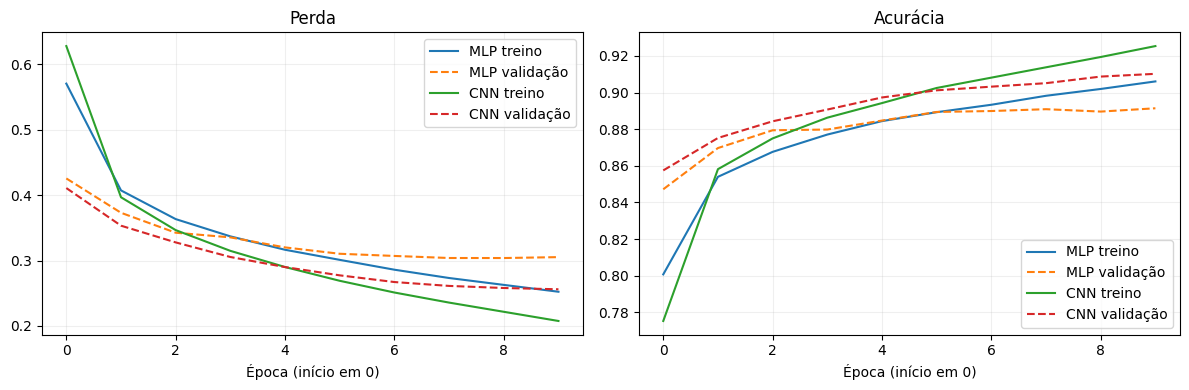

In [25]:
hist_cnn, tempo_cnn = treinar(cnn, X_train_cnn, y_train, X_val_cnn, y_val)
plotar_historicos({'MLP': hist_mlp, 'CNN': hist_cnn})

### Mapas de Características Aprendidos

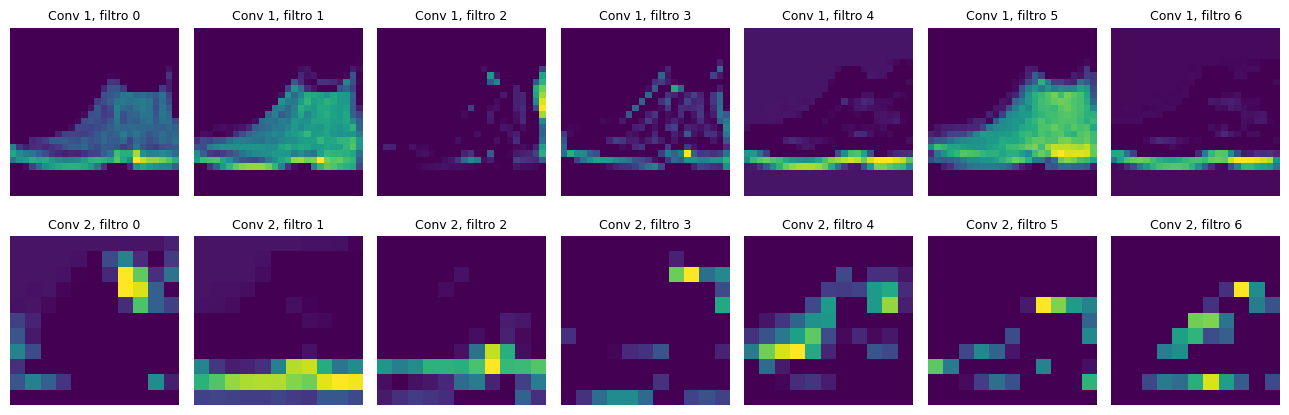

In [26]:
camadas_conv = [camada for camada in cnn.layers if isinstance(camada, layers.Conv2D)]
extrator = keras.Model(inputs=cnn.inputs, outputs=[camada.output for camada in camadas_conv])
mapas = extrator.predict(X_test_cnn[:1], verbose=0)
fig, axes = plt.subplots(2, 7, figsize=(13, 4.5))
for linha, mapa_conv in enumerate(mapas):
    for canal in range(7):
        axes[linha, canal].imshow(mapa_conv[0, :, :, canal], cmap='viridis')
        axes[linha, canal].axis('off')
        axes[linha, canal].set_title(f'Conv {linha+1}, filtro {canal}', fontsize=9)
plt.tight_layout(); plt.show()

## Comparação: MLP **versus** CNN


,Modelo,Parâmetros,Acurácia teste,Perda teste,Treinamento (s)
0,MLP,109386,0.8792,0.3403,12.6597
1,CNN,121930,0.8984,0.2773,65.2776


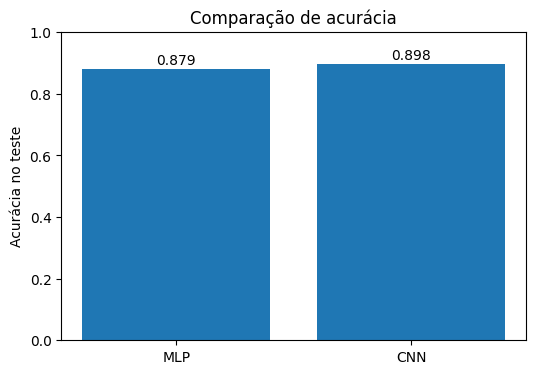

In [27]:
perda_mlp, acc_mlp = mlp.evaluate(X_test, y_test, verbose=0)
perda_cnn, acc_cnn = cnn.evaluate(X_test_cnn, y_test, verbose=0)
comparacao = pd.DataFrame([
    {'Modelo': 'MLP', 'Parâmetros': mlp.count_params(),
     'Acurácia teste': acc_mlp, 'Perda teste': perda_mlp, 'Treinamento (s)': tempo_mlp},
    {'Modelo': 'CNN', 'Parâmetros': cnn.count_params(),
     'Acurácia teste': acc_cnn, 'Perda teste': perda_cnn, 'Treinamento (s)': tempo_cnn}
])
display(comparacao.round(4))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(comparacao['Modelo'], comparacao['Acurácia teste'])
ax.set_ylim(0, 1); ax.set_ylabel('Acurácia no teste')
ax.set_title('Comparação de acurácia')
for i, v in enumerate(comparacao['Acurácia teste']):
    ax.text(i, v + .015, f'{v:.3f}', ha='center')
plt.show()

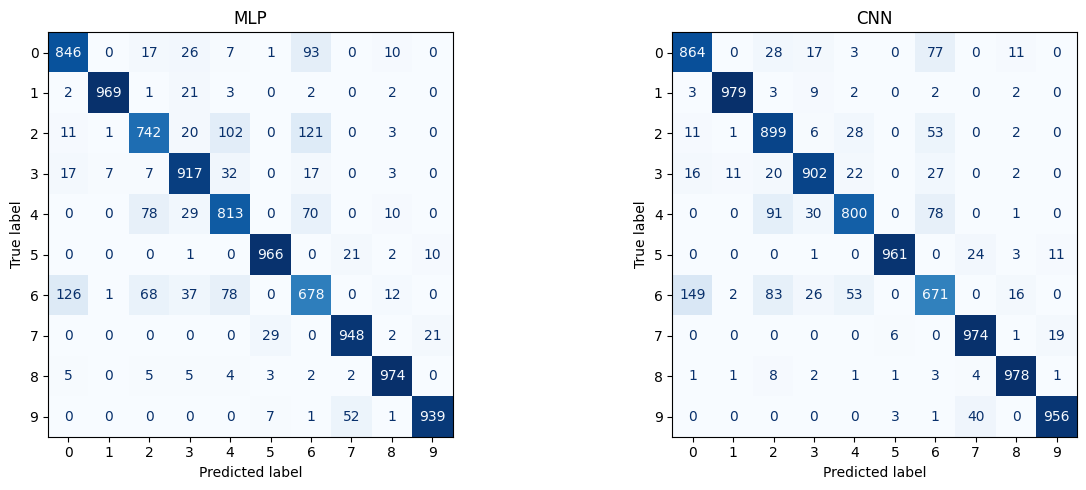

MLP:
               precision    recall  f1-score   support

Camiseta/top       0.84      0.85      0.84      1000
       Calça       0.99      0.97      0.98      1000
     Pulôver       0.81      0.74      0.77      1000
     Vestido       0.87      0.92      0.89      1000
      Casaco       0.78      0.81      0.80      1000
    Sandália       0.96      0.97      0.96      1000
      Camisa       0.69      0.68      0.68      1000
       Tênis       0.93      0.95      0.94      1000
       Bolsa       0.96      0.97      0.96      1000
        Bota       0.97      0.94      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

CNN:
               precision    recall  f1-score   support

Camiseta/top       0.83      0.86      0.85      1000
       Calça       0.98      0.98      0.98      1000
     Pulôver       0.79      0.90      0.84      1000
     Vestido

In [28]:
pred_mlp = np.argmax(mlp.predict(X_test, verbose=0), axis=1)
pred_cnn = np.argmax(cnn.predict(X_test_cnn, verbose=0), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, nome, preds in zip(axes, ['MLP', 'CNN'], [pred_mlp, pred_cnn]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, cmap='Blues',
                                            colorbar=False, values_format='d')
    ax.set_title(nome)
plt.tight_layout(); plt.show()
print('MLP:\n', classification_report(y_test, pred_mlp, target_names=nomes_classes))
print('CNN:\n', classification_report(y_test, pred_cnn, target_names=nomes_classes))

### Exemplos em que a MLP erra e a CNN acerta

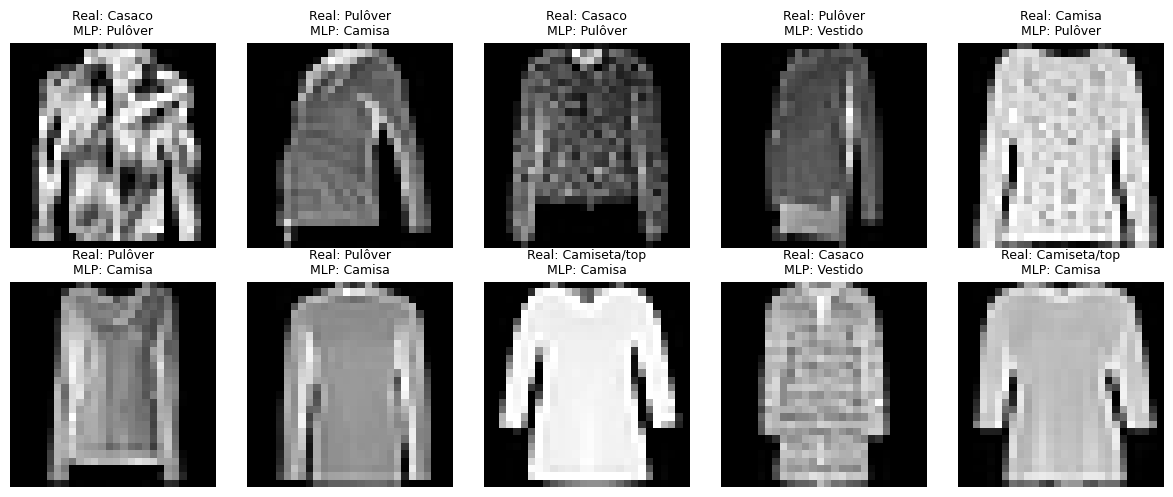

In [29]:
indices = np.flatnonzero((pred_mlp != y_test) & (pred_cnn == y_test))[:10]
if len(indices) == 0:
    print('Nenhum exemplo encontrado com esse critério nesta execução.')
else:
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, idx in zip(axes.flat, indices):
        ax.imshow(X_test[idx], cmap='gray')
        ax.set_title(f'Real: {nomes_classes[y_test[idx]]}\nMLP: {nomes_classes[pred_mlp[idx]]}', fontsize=9)
        ax.axis('off')
    for ax in axes.flat[len(indices):]: ax.axis('off')
    plt.tight_layout(); plt.show()